In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, StratifiedKFold, TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
PALETTE = {"Dummy": "#999999", "LogisticRegression": "#0072B2",
           "RandomForest": "#E69F00", "HistGradientBoosting": "#009E73",
           "XGBoost": "#D55E00", "LightGBM": "#CC79A7"}

pd.set_option("display.max_columns", None)

df = pd.read_csv("datascience.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# Bank Marketing: พยากรณ์ลูกค้าที่จะฝากประจำ (Term Deposit)

**เป้าหมาย:** สร้างโมเดลจำแนก (binary classification) เพื่อทำนายว่าลูกค้าคนไหนมีแนวโน้มจะ "ฝากประจำ" (`deposit` = yes/no) จากข้อมูลก่อน/ระหว่างแคมเปญการตลาดทางโทรศัพท์

**แนวทางการทำงาน**
1. สำรวจข้อมูล (EDA) + ตรวจสอบความไม่สมดุลของคลาส
2. จัดการ feature ที่มีปัญหา data leakage (`duration`)
3. แบ่ง train/test แบบ **ไม่สลับข้อมูล (time-based, no shuffle)** เพราะข้อมูลเรียงตามเวลาการติดต่อจริง → test set คือ "อนาคต" ที่โมเดลไม่เคยเห็น
4. อธิบายหลักการทำงานของแต่ละอัลกอริทึม classification ก่อนเริ่มสร้างโมเดลจริง (พร้อมภาพเปรียบเทียบ decision boundary)
5. ทดลองหลายโมเดล × หลายรูปแบบการแบ่งข้อมูล validation (K-Fold แบบสุ่ม, K-Fold ไม่สุ่ม, TimeSeriesSplit) เพื่อดูว่าผลลัพธ์ robust แค่ไหน
6. เลือกโมเดลที่ดีที่สุด ประเมินบน test set ที่ไม่เคยเห็นจริง ๆ ครั้งเดียว
7. ทดลองแบ่งสัดส่วน train:test หลายแบบ (60:40, 70:30, 80:20, 90:10) × หลายโมเดล เพื่อหาคู่ที่ดีที่สุด

## 1. สำรวจข้อมูล (EDA)

In [2]:
print("shape:", df.shape)
print()
print(df.dtypes)
print()
print("missing values:\n", df.isnull().sum().sum(), "(ไม่มี NaN แต่หลายคอลัมน์ใช้ค่า 'unknown' แทนข้อมูลที่ไม่มี)")
print()
for col in ["job", "education", "contact", "poutcome"]:
    print(f"{col}: unknown = {(df[col] == 'unknown').mean():.1%}")

shape: (45211, 17)

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

missing values:
 0 (ไม่มี NaN แต่หลายคอลัมน์ใช้ค่า 'unknown' แทนข้อมูลที่ไม่มี)

job: unknown = 0.6%
education: unknown = 4.1%
contact: unknown = 28.8%
poutcome: unknown = 81.7%


deposit
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


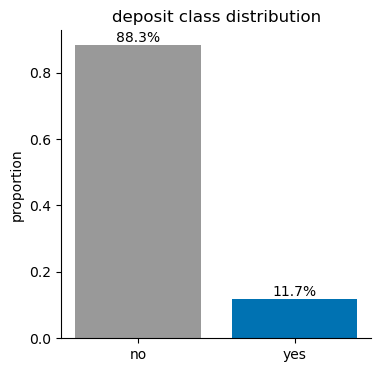

In [3]:
# การกระจายของ target -> ข้อมูลไม่สมดุล (imbalanced) ประมาณ 88% no / 12% yes
target_counts = df["deposit"].value_counts(normalize=True)
print(target_counts)

fig, ax = plt.subplots(figsize=(4, 4))
ax.bar(target_counts.index, target_counts.values,
       color=[PALETTE["Dummy"], PALETTE["LogisticRegression"]])
ax.set_ylabel("proportion")
ax.set_title("deposit class distribution")
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### ยืนยันว่าข้อมูลเรียงตามเวลา

ไม่มีคอลัมน์ปี/วันที่ตรง ๆ แต่มี `month` และ `day` ของการติดต่อครั้งล่าสุด ลองแปลง `month` เป็นตัวเลขแล้วไล่ดูว่าลำดับแถวใน DataFrame สอดคล้องกับลำดับเวลาจริงหรือไม่

In [4]:
MONTH_ORDER = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_num = df["month"].map({m: i for i, m in enumerate(MONTH_ORDER)})

# เดือนควรจะ "ไม่ลดลง" เมื่อไล่ตาม index ยกเว้นตอนข้ามปี (ธ.ค. -> ม.ค.)
n_decreases = (month_num.diff() < 0).sum()
print(f"จำนวนครั้งที่เดือนลดลงเมื่อไล่ตาม index: {n_decreases} ครั้ง (ตรงกับจำนวนรอบปีของแคมเปญ)")
print("=> ข้อมูลถูกเรียงตามเวลาการติดต่อลูกค้าอยู่แล้ว: แถวบนสุด = เก่าสุด, แถวล่างสุด = ใหม่สุด")

จำนวนครั้งที่เดือนลดลงเมื่อไล่ตาม index: 2 ครั้ง (ตรงกับจำนวนรอบปีของแคมเปญ)
=> ข้อมูลถูกเรียงตามเวลาการติดต่อลูกค้าอยู่แล้ว: แถวบนสุด = เก่าสุด, แถวล่างสุด = ใหม่สุด


### ⚠️ ข้อสังเกตสำคัญ: `duration` รั่วไหลข้อมูลจากอนาคต (data leakage)

`duration` คือ "ความยาวการโทรครั้งล่าสุด" ซึ่งจะทราบค่าได้ **ก็ต่อเมื่อโทรไปแล้ว** (และมักมีค่าใกล้ 0 วินาทีถ้าลูกค้าปฏิเสธทันที) ถ้าเป้าหมายของโมเดลคือ "เลือกว่าจะโทรไปหาใครก่อนโทร" เราจะไม่มีค่า `duration` ล่วงหน้า การใส่ฟีเจอร์นี้เข้าไปจะทำให้โมเดลดูแม่นยำสูงเกินจริงแบบหลอกตา (optimistic bias)

**แนวทาง:** ตัด `duration` ออกจากฟีเจอร์หลักที่ใช้ train จริง และทำการทดลองเสริมท้ายสุดเพื่อโชว์ผลต่างให้เห็นชัด ๆ ว่าเกิด leakage มากแค่ไหนถ้าใส่เข้าไป

## 2. Feature engineering

In [5]:
model_df = df.copy()

# pdays == -1 หมายถึง "ไม่เคยติดต่อมาก่อน" -> แยกเป็น flag แล้วแทนค่า -1 ด้วย 0 (ไม่ให้ทำลายสเกล)
model_df["was_contacted_before"] = (model_df["pdays"] != -1).astype(int)
model_df["pdays"] = model_df["pdays"].clip(lower=0)

model_df["y"] = (model_df["deposit"] == "yes").astype(int)

CATEGORICAL_FEATURES = ["job", "marital", "education", "default", "housing",
                         "loan", "contact", "month", "poutcome"]
NUMERIC_FEATURES = ["age", "balance", "day", "campaign", "pdays", "previous",
                     "was_contacted_before"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES  # ไม่รวม duration โดยตั้งใจ

X = model_df[FEATURES]
y = model_df["y"]
print(X.shape, y.shape)

(45211, 16) (45211,)


## 3. แบ่ง Train / Test: time-based split (ไม่สลับข้อมูล)

**คำแนะนำ: ไม่ควรสลับ (shuffle) ตอนแบ่ง train/test หลัก** เพราะ:

- ข้อมูลเรียงตามเวลาจริง การสุ่มแบ่งแบบ shuffle จะทำให้ตัวอย่างจาก "ช่วงเวลาเดียวกัน" (เช่น โทรวันเดียวกัน ภาวะเศรษฐกิจ/อัตราดอกเบี้ยช่วงเดียวกัน) หลุดไปอยู่ทั้ง train และ test พร้อมกัน ทำให้ตัวเลข validation ดูดีเกินจริง (optimistic bias)
- Use case จริงคือ "ใช้ข้อมูลแคมเปญที่ผ่านมา พยากรณ์ลูกค้าในแคมเปญถัดไป" ซึ่งเป็นสถานการณ์ time-based โดยธรรมชาติ — test set ควรเป็น "อนาคต" ที่โมเดลไม่เคยเห็นจริง ๆ ทั้งในมิติของตัวอย่างและเวลา
- เราได้ยืนยันแล้วว่าแถวบนสุด = เก่าสุด ดังนั้นตัดแบบ positional (80% แรก = train, 20% ท้าย = test) โดยไม่ sort/shuffle ซ้ำ

เพื่อให้เห็นผลต่าง เราจะสร้าง random split (แบบ stratified shuffle) ไว้เปรียบเทียบด้วยในภายหลัง แต่จะไม่ใช้เป็นตัวตัดสินผลสุดท้าย

In [6]:
split_idx = int(len(X) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"train: {X_train.shape[0]} แถว (deposit=yes {y_train.mean():.1%})")
print(f"test : {X_test.shape[0]} แถว (deposit=yes {y_test.mean():.1%})")
print(f"เดือนสุดท้ายของ train: {df['month'].iloc[split_idx - 1]} | เดือนแรกของ test: {df['month'].iloc[split_idx]}")

train: 36168 แถว (deposit=yes 6.7%)
test : 9043 แถว (deposit=yes 31.6%)
เดือนสุดท้ายของ train: may | เดือนแรกของ test: may


## 4. หลักการทำงานของโมเดล Classification (ก่อนเริ่มสร้างโมเดล)

**Classification คืออะไร:** โมเดลเรียนรู้ฟังก์ชัน $f$ ที่แปลงฟีเจอร์ของลูกค้า $x$ (อายุ, อาชีพ, ยอดเงินในบัญชี, ฯลฯ) ให้เป็น **ความน่าจะเป็น** ที่ลูกค้าจะฝากประจำ $\hat{p} = f(x) \in [0, 1]$ จากนั้นตั้ง threshold (ปกติ 0.5) เพื่อตัดสินเป็นคลาส `yes`/`no`

**หลักการ train/evaluate ที่ใช้ร่วมกันทุกโมเดล:**
1. โมเดลปรับพารามิเตอร์ภายในให้ **loss บน train set ต่ำที่สุด** (เช่น log-loss สำหรับ classification)
2. ถ้าปรับจนเก่งกับ train set มากเกินไปจะเกิด **overfitting** — ทำนายข้อมูลใหม่ได้แย่ ทั้งที่ดูดีตอน train นี่คือเหตุผลที่ต้องมี test set แยกต่างหาก (ข้อ 3) และ cross-validation (ข้อ 6) มาคอยตรวจสอบ
3. โมเดลแต่ละแบบ "เดา" รูปร่างของ decision boundary (เส้นแบ่งระหว่างคลาส) ไม่เหมือนกัน — นี่คือจุดที่ทำให้แต่ละอัลกอริทึมเหมาะกับข้อมูลต่างรูปแบบกัน ลองดูภาพเปรียบเทียบท้ายข้อนี้

ตารางสรุป 4 โมเดลที่ใช้ในการทดลองนี้:

| โมเดล | หลักการ | จุดเด่น | จุดอ่อน |
|---|---|---|---|
| **Dummy** (baseline) | ทายคลาสส่วนใหญ่ (`no`) ทุกครั้ง ไม่เรียนรู้อะไรจากฟีเจอร์เลย | ใช้เป็น "พื้นว่าง" เทียบว่าโมเดลจริงเก่งกว่าการเดามั่ว ๆ แค่ไหน | ทำนายไม่ได้จริง ไม่มีประโยชน์ใช้งาน |
| **Logistic Regression** | หาเส้นตรง (เส้นตรง/ไฮเปอร์เพลน) แบ่งสองคลาส จาก weighted sum ของฟีเจอร์ แล้วบีบผลด้วย sigmoid ให้เป็นความน่าจะเป็น | เร็ว ตีความได้ (ดูน้ำหนัก/ทิศทางของแต่ละฟีเจอร์ได้ตรง ๆ) ไม่ overfit ง่าย | จับความสัมพันธ์แบบไม่เป็นเส้นตรง (non-linear) หรือ interaction ระหว่างฟีเจอร์ไม่ได้ถ้าไม่สร้างฟีเจอร์เพิ่มเอง |
| **Random Forest** | สร้าง decision tree หลายร้อยต้น แต่ละต้น train บนข้อมูลสุ่ม (bootstrap) + ฟีเจอร์สุ่มบางส่วน แล้ว "โหวต" ค่าเฉลี่ยความน่าจะเป็นจากทุกต้น (bagging) | จับความสัมพันธ์ไม่เป็นเส้นตรงและ interaction ได้ดี ทนต่อ overfitting กว่า tree เดี่ยว | ตีความยากกว่า logistic regression โมเดลมีขนาดใหญ่/ช้ากว่า |
| **HistGradientBoosting** | สร้าง decision tree ตื้น ๆ ทีละต้น "ต่อเนื่องกัน" โดยต้นใหม่เรียนรู้จาก **ความผิดพลาดที่เหลือ (residual error)** ของกลุ่มต้นก่อนหน้า (boosting) ใช้เทคนิค histogram-binning ฟีเจอร์ตัวเลขให้เร็วขึ้น | มักให้ความแม่นยำสูงสุดในงาน tabular data ส่วนใหญ่ จับ pattern ซับซ้อนได้ดี | ปรับ hyperparameter ยากกว่า เสี่ยง overfit ถ้าตั้งค่าไม่ดี train ต่อเนื่องทำให้ parallelize ยากกว่า RF |

### ภาพเปรียบเทียบ decision boundary

ทดลองกับข้อมูลของเล่น 2 มิติ (2 ฟีเจอร์, 2 คลาส) ที่มีรูปแบบโค้งไม่เป็นเส้นตรง (`make_moons`) เพื่อให้เห็นภาพว่าแต่ละอัลกอริทึมตัดสินใจแบ่งคลาสต่างกันอย่างไร:
- **Logistic Regression** → เส้นแบ่งเป็น **เส้นตรง** เส้นเดียว (เพราะเป็น weighted sum ของฟีเจอร์)
- **Random Forest** → เส้นแบ่งเป็น **บล็อกสี่เหลี่ยมขั้นบันได** (เพราะ tree แต่ละต้นถาม "ฟีเจอร์นี้ > ค่านี้หรือไม่" ทีละแกน) แต่เฉลี่ยจากหลายต้นทำให้ขอบเรียบขึ้น
- **HistGradientBoosting** → เส้นแบ่งเป็นบล็อกเช่นกันแต่ซับซ้อนกว่า เพราะต้นไม้แต่ละต้นถูกเพิ่มเข้ามาเพื่อแก้ตรงจุดที่ยังทำนายผิดอยู่

ข้อมูลจริงของเราไม่ใช่ 2 มิติและไม่ได้สวยงามขนาดนี้ (ดู ROC-AUC ~0.68 ในข้อ 7) แต่หลักการตัดสินใจเบื้องหลังเหมือนกันทุกประการ

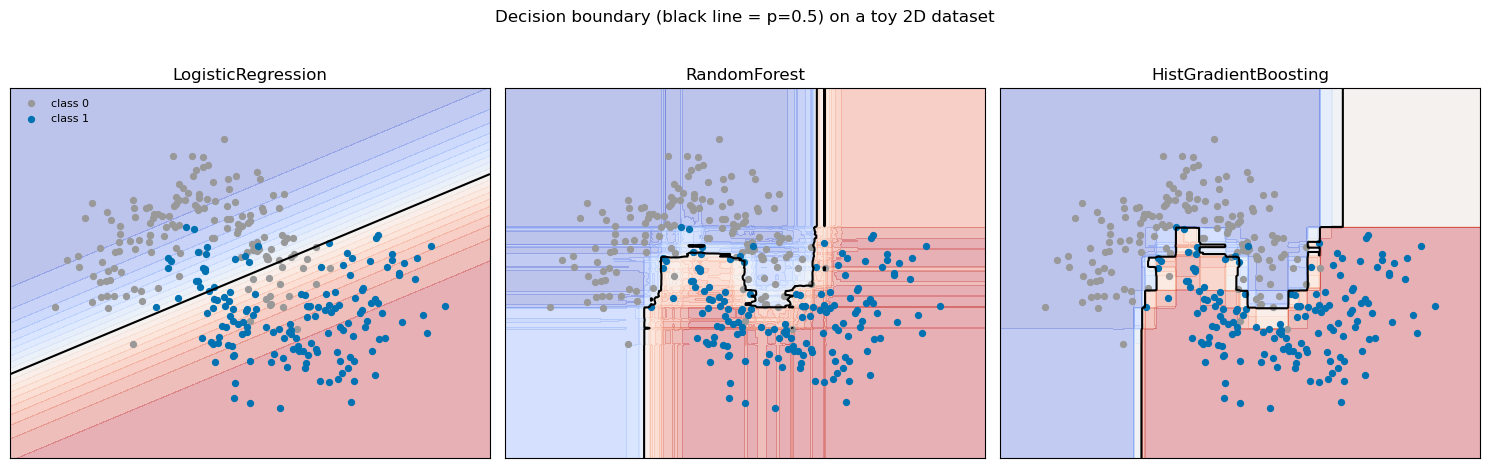

In [7]:
from sklearn.datasets import make_moons

X_toy, y_toy = make_moons(n_samples=300, noise=0.25, random_state=RANDOM_STATE)

toy_models = {
    "LogisticRegression": LogisticRegression(),
    "RandomForest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_depth=3, random_state=RANDOM_STATE),
}

xx, yy = np.meshgrid(np.linspace(X_toy[:, 0].min() - 0.5, X_toy[:, 0].max() + 0.5, 300),
                      np.linspace(X_toy[:, 1].min() - 0.5, X_toy[:, 1].max() + 0.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, toy_models.items()):
    model.fit(X_toy, y_toy)
    proba_grid = model.predict_proba(grid)[:, 1].reshape(xx.shape)

    ax.contourf(xx, yy, proba_grid, levels=20, cmap="coolwarm", alpha=0.35)
    ax.contour(xx, yy, proba_grid, levels=[0.5], colors="black", linewidths=1.5)
    ax.scatter(X_toy[y_toy == 0, 0], X_toy[y_toy == 0, 1], c=PALETTE["Dummy"], s=18, label="class 0")
    ax.scatter(X_toy[y_toy == 1, 0], X_toy[y_toy == 1, 1], c=PALETTE["LogisticRegression"], s=18, label="class 1")
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

axes[0].legend(frameon=False, loc="upper left", fontsize=8)
plt.suptitle("Decision boundary (black line = p=0.5) on a toy 2D dataset", y=1.03)
plt.tight_layout()
plt.show()

### อ่านกราฟ decision boundary ด้านบน: ทำไมผลลัพธ์จริงถึงออกมาแบบนั้น

กราฟข้างบนใช้ข้อมูลของเล่น (toy data) 2 มิติเพื่อให้ "เห็นภาพ" ว่าโมเดลแต่ละแบบตัดสินใจต่างกันอย่างไร โดยเส้น/ขอบเขตสีดำคือจุดที่โมเดลเปลี่ยนคำตอบจาก class 0 → class 1 (p=0.5):

- **LogisticRegression** วาดได้แค่เส้นตรง (hyperplane) เท่านั้น — **bias สูง, variance ต่ำ** โมเดลไม่มีความยืดหยุ่นพอจะไปตามจุดข้อมูลแปลก ๆ ทีละจุด ดังนั้นต่อให้ข้อมูล train เปลี่ยนไปบ้าง เส้นก็จะไม่ขยับมาก
- **RandomForest / HistGradientBoosting** วาดขอบเขตเป็นรูปทรงซับซ้อน หยักไปตามจุดข้อมูลได้ละเอียดกว่า — **bias ต่ำ, variance สูง** คือจุดแข็งเวลาข้อมูล train/test มาจากการสุ่มแบบเดียวกัน แต่เป็นจุดอ่อนเวลาต้องทำนาย "อนาคต" ที่ pattern อาจไม่เหมือนเดิมเป๊ะ เพราะโมเดลอาจไป fit จุดที่เป็น noise เฉพาะช่วงเวลานั้น ๆ

**นี่คือเหตุผลเบื้องหลังตัวเลขจริงในหัวข้อ 6:** พอเปลี่ยนจาก `StratifiedKFold(shuffle=True)` ไปเป็น `TimeSeriesSplit` คะแนน ROC-AUC ของ RandomForest/HistGradientBoosting/XGBoost ร่วงแรงกว่า LogisticRegression มาก (เช่น HistGradientBoosting 0.712 → 0.542) เพราะโมเดลกลุ่มนี้เคย "จำ" pattern เฉพาะช่วงเวลาที่เห็นตอน train ได้ละเอียดเกินไป (overfit ต่อช่วงเวลา) พอเจอช่วงเวลาใหม่จริง ๆ ความแม่นยำที่ดูดีเกินจริงก็หายไป


## 5. Preprocessing pipeline

In [8]:
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ("num", StandardScaler(), NUMERIC_FEATURES),
])

## 6. หลายโมเดล × หลายรูปแบบการแบ่ง validation

เทียบ 6 โมเดล (รวม baseline) ด้วย 3 รูปแบบการแบ่งข้อมูล validation บน **train set เท่านั้น** (ยังไม่แตะ test set):

| รูปแบบ | ลักษณะ | เหมาะกับ |
|---|---|---|
| `StratifiedKFold(shuffle=True)` | สุ่มสลับ แบ่งสัดส่วนคลาสเท่ากันทุก fold | เทียบ "ความแรง" ของแต่ละโมเดล แบบมาตรฐานทั่วไป |
| `KFold(shuffle=False)` | ไม่สุ่ม ตัดเป็นช่วงต่อเนื่องตามเวลา (block CV) | ดูว่าโมเดลเสถียรข้ามช่วงเวลาต่าง ๆ แค่ไหน |
| `TimeSeriesSplit` | expanding window, train อยู่ก่อน test เสมอ | จำลองสถานการณ์จริงที่สุด (ไม่มีอนาคตรั่วเข้าไปใน train) |

โมเดลที่ใช้: `LogisticRegression`, `RandomForestClassifier`, `HistGradientBoostingClassifier`, `XGBClassifier`, `LGBMClassifier` และ `DummyClassifier` (baseline เทียบเฉย ๆ) — เพิ่ม XGBoost/LightGBM เข้ามาเพราะเป็นมาตรฐานอุตสาหกรรมสำหรับ tabular data (ก่อนหน้านี้ไม่ได้ใช้เพราะไม่ได้ติดตั้งในเครื่อง ตอนนี้ติดตั้งแล้ว)

In [9]:
# clone() กันไม่ให้ fit ทับ object โมเดลเดิมซ้ำ ๆ ข้ามหลายส่วนของโน้ตบุ๊ก (บาง estimator เช่น LightGBM
# ไม่ยอมให้ fit ซ้ำด้วยจำนวนฟีเจอร์ต่างไปจากเดิมบน object เดียวกัน)
from sklearn.base import clone

def make_pipeline(estimator):
    return Pipeline([("prep", clone(preprocessor)), ("clf", clone(estimator))])

# XGBoost ไม่มี class_weight="balanced" แบบโมเดลอื่น ต้องคำนวณ scale_pos_weight เอง
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

MODELS = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(
        n_estimators=200, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1, eval_metric="logloss",
        scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    ),
}

CV_SCHEMES = {
    "StratifiedKFold(shuffle)": StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    "KFold(no shuffle)": KFold(n_splits=5, shuffle=False),
    "TimeSeriesSplit": TimeSeriesSplit(n_splits=5),
}

SCORING = {"roc_auc": "roc_auc", "f1": "f1", "pr_auc": "average_precision"}

results = []
for cv_name, cv in CV_SCHEMES.items():
    for model_name, estimator in MODELS.items():
        scores = cross_validate(make_pipeline(estimator), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
        results.append({
            "cv_scheme": cv_name,
            "model": model_name,
            "roc_auc": scores["test_roc_auc"].mean(),
            "f1": scores["test_f1"].mean(),
            "pr_auc": scores["test_pr_auc"].mean(),
        })

results_df = pd.DataFrame(results)
results_df.pivot(index="model", columns="cv_scheme", values="roc_auc").round(3)

cv_scheme,KFold(no shuffle),StratifiedKFold(shuffle),TimeSeriesSplit
model,,,
Dummy,0.500,0.500,0.500
HistGradientBoosting,0.551,0.712,0.542
LightGBM,0.572,0.697,0.532
LogisticRegression,0.553,0.685,0.540
RandomForest,0.567,0.693,0.522
XGBoost,0.572,0.691,0.524


In [ ]:
# กราฟเปรียบเทียบ ROC-AUC: จัดกลุ่มตาม cv_scheme แกน x, แต่ละโมเดลสีคงที่ (ตาม PALETTE) ทุกกลุ่ม
cv_names = list(CV_SCHEMES.keys())
model_names = list(MODELS.keys())
n_models = len(model_names)
bar_width = 0.8 / n_models
x = np.arange(len(cv_names))

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, model_name in enumerate(model_names):
    vals = [results_df[(results_df.cv_scheme == cv) & (results_df.model == model_name)]["roc_auc"].iloc[0]
            for cv in cv_names]
    ax.bar(x + i * bar_width - 0.4 + bar_width / 2, vals, width=bar_width,
           label=model_name, color=PALETTE[model_name])

ax.set_xticks(x)
ax.set_xticklabels(cv_names)
ax.set_ylabel("ROC-AUC (mean of 5-fold CV)")
ax.set_ylim(0.4, 1.0)
ax.set_title("Model comparison across CV schemes (on train set)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), borderaxespad=0, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### เหตุผลที่แต่ละโมเดลได้คะแนนแบบนี้ (อ่านประกอบตารางด้านบน)

**Dummy (baseline):** 0.500 ทุก scheme — เป็นไปตามนิยาม (ทายคลาสเดียวตลอด ROC-AUC ของการเดามั่วคือ 0.5 เป๊ะ) ใช้เป็นพื้นล่างสุดเพื่อยืนยันว่าโมเดลอื่น "เรียนรู้อะไรจริง" ไม่ใช่เรื่องบังเอิญ

**Logistic Regression:** 0.685 (shuffled) → 0.553 (no-shuffle) → 0.540 (TimeSeriesSplit) — คะแนนลดลงตาม scheme ที่ realistic ขึ้นเหมือนโมเดลอื่น แต่ **ลดลงน้อยที่สุด** เพราะเป็นเส้นตรง/ไฮเปอร์เพลนเดียว ไม่มี capacity พอจะไป overfit จับ pattern เฉพาะช่วงเวลาของ train set ได้ลึกเท่าโมเดลซับซ้อน ผลคือเมื่อย้ายไปสถานการณ์จริง (TimeSeriesSplit) กลับแซงหน้า Random Forest (0.522) และ XGBoost (0.524) ได้ และในข้อ 10 (ทดลองสัดส่วน) ก็เป็นคู่ที่ดีที่สุดโดยรวม (0.684 @ 80:20)

**Random Forest:** 0.693 (shuffled) → 0.522 (TimeSeriesSplit) — **ร่วงแรงที่สุดในบรรดาทุกโมเดล** เพราะ bagging สร้าง tree หลายร้อยต้นจากการสุ่มตัวอย่างซ้ำ (bootstrap) ของ train set เดียวกัน ทำให้แต่ละต้นมีแนวโน้ม "จำ" ลักษณะเฉพาะของช่วงเวลานั้น (เช่น อัตราดอกเบี้ย/บรรยากาศเศรษฐกิจตอนนั้น) เมื่อเจอข้อมูลช่วงเวลาถัดไปที่ pattern เปลี่ยนไป จึง generalize ได้แย่กว่าที่ CV แบบสุ่มบอกไว้มาก

**HistGradientBoosting:** แรงสุดใน 2 ใน 3 scheme (0.712 shuffled, 0.542 TimeSeriesSplit) — การ boosting ที่สร้าง tree ทีละต้นเพื่อแก้ residual error ของต้นก่อนหน้า ทำให้จับ pattern ที่ซับซ้อนกว่า bagging ได้ และยังรักษาอันดับ 1 ไว้ได้แม้ใน TimeSeriesSplit จึงถูกเลือกเป็น `best_model_name` — **แต่ส่วนต่างจาก Logistic Regression (0.542 vs 0.540) บางมากจนถือว่าเสมอกันทางสถิติ** ไม่ใช่ชัยชนะขาดลอย

**XGBoost / LightGBM:** แรงใกล้เคียง HistGradientBoosting ใน shuffled CV (0.691, 0.697) และเป็นผู้นำร่วมใน KFold(no shuffle) (0.572 เท่ากันทั้งคู่) แต่กลับร่วงมาอยู่กลาง-ท้ายตารางใน TimeSeriesSplit (0.524, 0.532) และในข้อ 10 ก็ไม่เคยติด 2 อันดับแรกเลย (ดีสุดคือ LightGBM 0.643 @ 70:30) ทั้งที่โดยทฤษฎีควรแรงพอ ๆ กับ HistGradientBoosting เพราะใช้หลักการ histogram-based boosting แบบเดียวกัน — ส่วนต่างนี้น่าจะมาจาก **hyperparameter ที่ยังไม่ได้ tune เฉพาะทาง** (ใช้ค่ากลาง ๆ เดียวกันทุกโมเดลเพื่อให้เทียบกันแฟร์) มากกว่าข้อจำกัดของอัลกอริทึมเอง — ถ้าจะให้ทั้งคู่แข่งขันได้เต็มที่ต้องทำ hyperparameter tuning เพิ่ม (เช่น `GridSearchCV`/Optuna) ซึ่งอยู่นอกขอบเขตการทดลองเปรียบเทียบเบื้องต้นนี้

**ภาพรวมที่สำคัญที่สุด:** ทุกโมเดลที่ซับซ้อนกว่า Logistic Regression (RF, XGBoost, LightGBM, และแม้แต่ HistGradientBoosting บางส่วน) **ร่วงแรงกว่า LR เสมอ** เมื่อเปลี่ยนจาก shuffled CV ไป TimeSeriesSplit — ยืนยันประเด็นเดียวกับ Appendix A ว่า shuffle ทำให้ตัวเลขดูดีเกินจริง (optimistic bias) และยิ่งโมเดลซับซ้อน/มี capacity สูง ยิ่งถูกเอฟเฟกต์นี้บิดเบือนมาก เพราะมันมีความสามารถไป fit กับสัญญาณเฉพาะช่วงเวลาได้มากกว่าโมเดลง่าย ๆ

## 7. เลือกโมเดลที่ดีที่สุด แล้วประเมินบน test set ที่ไม่เคยเห็น

เลือกโมเดลที่ให้ `roc_auc` เฉลี่ยสูงสุดจาก `TimeSeriesSplit` (schema ที่ realistic ที่สุด) แล้ว **fit ด้วย train set ทั้งหมด** ครั้งเดียว และประเมินผลบน `X_test`/`y_test` (20% ท้ายสุด ซึ่งเป็นช่วงเวลาที่โมเดลไม่เคยเห็นเลย) เพียงครั้งเดียวเท่านั้น

In [11]:
best_model_name = (
    results_df[results_df.cv_scheme == "TimeSeriesSplit"]
    .set_index("model")["roc_auc"]
    .idxmax()
)
print("โมเดลที่เลือก:", best_model_name)

best_pipeline = make_pipeline(MODELS[best_model_name])
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"\nTest ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(f"Test PR-AUC : {average_precision_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))

โมเดลที่เลือก: HistGradientBoosting

Test ROC-AUC: 0.680
Test PR-AUC : 0.468

              precision    recall  f1-score   support

          no       0.70      0.97      0.81      6187
         yes       0.53      0.08      0.14      2856

    accuracy                           0.69      9043
   macro avg       0.61      0.52      0.48      9043
weighted avg       0.64      0.69      0.60      9043



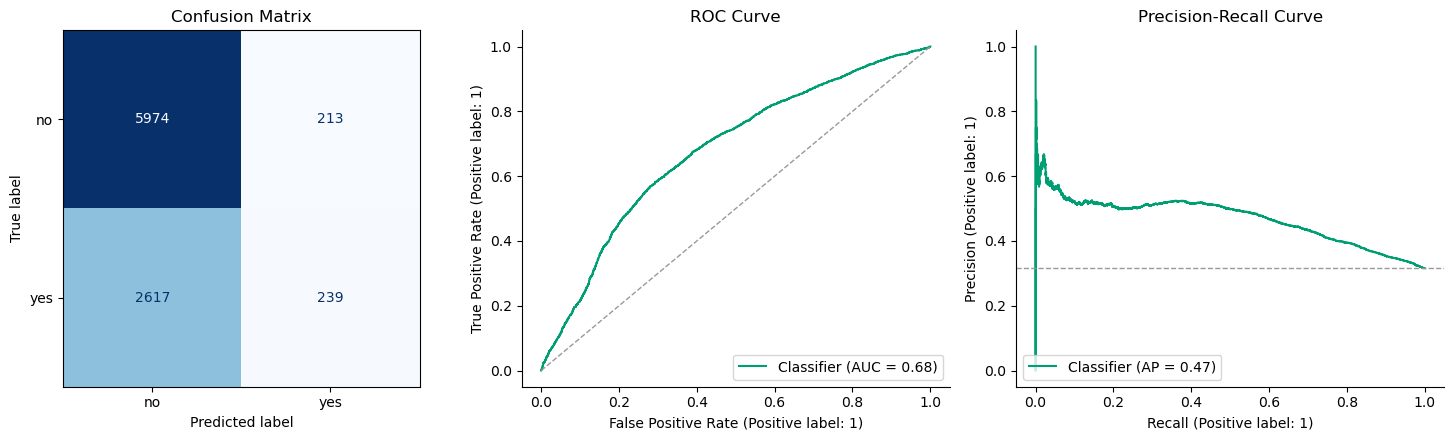

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["no", "yes"], cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], color=PALETTE[best_model_name])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="#999999", linewidth=1)
axes[1].set_title("ROC Curve")
axes[1].spines[["top", "right"]].set_visible(False)

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2], color=PALETTE[best_model_name])
axes[2].axhline(y_test.mean(), linestyle="--", color="#999999", linewidth=1, label="baseline")
axes[2].set_title("Precision-Recall Curve")
axes[2].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### ปรับ decision threshold เพื่อ "ไม่พลาด" ลูกค้าที่จะฝากประจำ (เพิ่ม recall)

จากผลด้านบน ที่ threshold เริ่มต้น 0.5 โมเดลจับลูกค้าที่จะฝากประจำจริงได้แค่ **8.4%** (false negative สูงมาก) เพราะ 0.5 เป็นจุดตัดที่เข้มเกินไปสำหรับข้อมูลไม่สมดุลแบบนี้ — ทางแก้คือ **ลด threshold ลง** เพื่อให้โมเดลยอม "เสี่ยงทัก" ลูกค้ามากขึ้น แลกกับ precision ที่ลดลง (โทรผิดเป้าบ้าง)

**วิธีเลือก threshold โดยไม่ทำให้เกิด leakage:** ห้ามใช้ test set มาช่วยเลือก threshold เพราะจะกลายเป็นแอบดูคำตอบ ดังนั้นตัด validation set จากท้าย ๆ ของ train set เอง (ยังคง time-based) มาหา threshold ที่ **recall ≥ 80%** โดยเลือกจุดที่ precision ดีที่สุดในกลุ่มนั้น แล้วค่อยนำ threshold นี้ไปใช้กับ test set เพียงครั้งเดียวเพื่อรายงานผลจริง

In [13]:
from sklearn.metrics import precision_recall_curve

# ตัด validation จากท้าย train set เอง (time-based) เพื่อหา threshold โดยไม่แตะ test set
val_idx = int(len(X_train) * 0.8)
X_tr_inner, X_val = X_train.iloc[:val_idx], X_train.iloc[val_idx:]
y_tr_inner, y_val = y_train.iloc[:val_idx], y_train.iloc[val_idx:]

threshold_pipeline = make_pipeline(MODELS[best_model_name])
threshold_pipeline.fit(X_tr_inner, y_tr_inner)
val_proba = threshold_pipeline.predict_proba(X_val)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(y_val, val_proba)
precisions, recalls = precisions[:-1], recalls[:-1]  # ตัดจุดสุดท้ายออกให้ความยาวตรงกับ pr_thresholds

print(f"validation size: {len(X_val)} แถว (deposit=yes {y_val.mean():.1%})")

validation size: 7234 แถว (deposit=yes 13.7%)


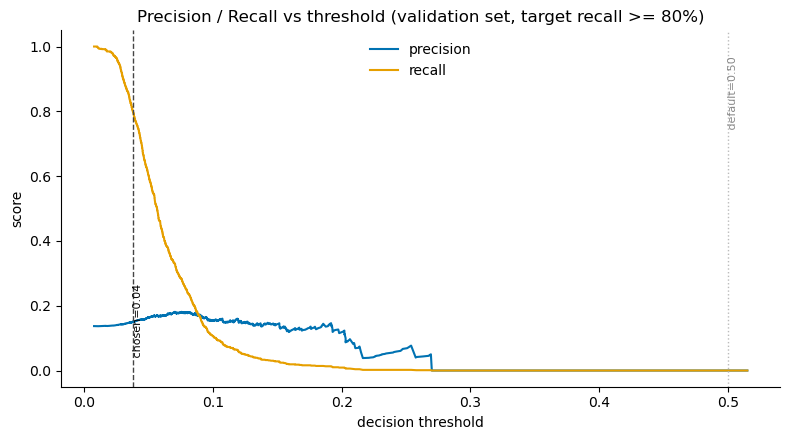

เลือก threshold = 0.038
บน validation: recall=80.1%, precision=15.1%


In [14]:
TARGET_RECALL = 0.80

mask = recalls >= TARGET_RECALL
candidate_precisions = np.where(mask, precisions, -1)
best_idx = np.argmax(candidate_precisions)
chosen_threshold = pr_thresholds[best_idx]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pr_thresholds, precisions, color=PALETTE["LogisticRegression"], label="precision")
ax.plot(pr_thresholds, recalls, color=PALETTE["RandomForest"], label="recall")
ax.axvline(chosen_threshold, color="#444444", linestyle="--", linewidth=1)
ax.axvline(0.5, color="#bbbbbb", linestyle=":", linewidth=1)
ax.text(chosen_threshold, 0.03, f" chosen={chosen_threshold:.2f}", rotation=90, va="bottom", fontsize=8)
ax.text(0.5, 0.97, " default=0.50", rotation=90, va="top", fontsize=8, color="#888888")
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title(f"Precision / Recall vs threshold (validation set, target recall >= {TARGET_RECALL:.0%})")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"เลือก threshold = {chosen_threshold:.3f}")
print(f"บน validation: recall={recalls[best_idx]:.1%}, precision={precisions[best_idx]:.1%}")

=== threshold เริ่มต้น 0.50 (test set) ===
              precision    recall  f1-score   support

          no       0.70      0.97      0.81      6187
         yes       0.53      0.08      0.14      2856

    accuracy                           0.69      9043
   macro avg       0.61      0.52      0.48      9043
weighted avg       0.64      0.69      0.60      9043

=== threshold ปรับใหม่ 0.038 (test set) ===
              precision    recall  f1-score   support

          no       0.87      0.08      0.14      6187
         yes       0.33      0.97      0.49      2856

    accuracy                           0.36      9043
   macro avg       0.60      0.53      0.32      9043
weighted avg       0.70      0.36      0.25      9043



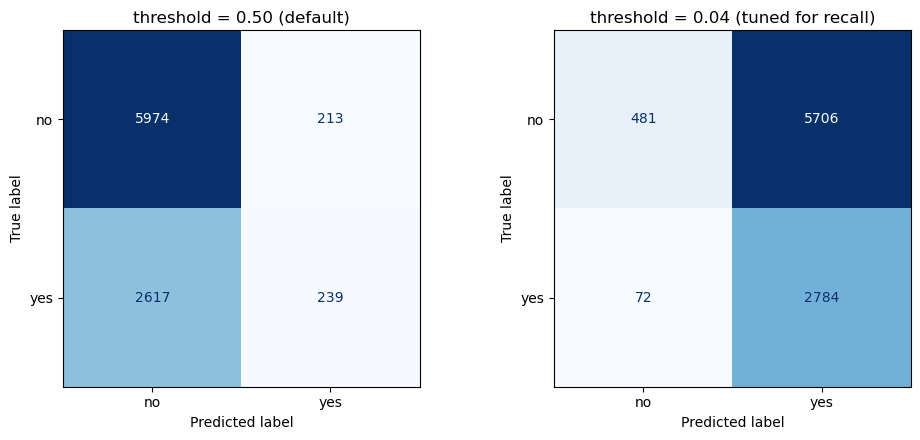

In [15]:
y_pred_tuned = (y_proba >= chosen_threshold).astype(int)

print("=== threshold เริ่มต้น 0.50 (test set) ===")
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))

print(f"=== threshold ปรับใหม่ {chosen_threshold:.3f} (test set) ===")
print(classification_report(y_test, y_pred_tuned, target_names=["no", "yes"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["no", "yes"], cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("threshold = 0.50 (default)")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tuned, display_labels=["no", "yes"], cmap="Blues", ax=axes[1], colorbar=False
)
axes[1].set_title(f"threshold = {chosen_threshold:.2f} (tuned for recall)")
plt.tight_layout()
plt.show()

### ⚠️ ทำไม threshold ที่ tune ไว้ถึงใช้ไม่ได้จริง — และทางแก้ที่ robust กว่า

ตัวเลขข้างบนดูเหมือนดี (recall `yes` = 97%) แต่ดูให้ลึกจะเห็นปัญหา: `recall` ของฝั่ง `no` เหลือแค่ 8% แปลว่าโมเดลทักว่า "yes" เกือบทุกคน (ประมาณ **93% ของลูกค้าทั้งหมด**) — เท่ากับโทรหาเกือบทุกคนในชุด test ซึ่งไม่ต่างจาก "ไม่กรองเลย" จึงใช้งานจริงไม่ได้

**สาเหตุ:** validation set (ตัดจากท้าย train) มีสัดส่วน `deposit=yes` แค่ **13.7%** แต่ test set (ช่วงเวลาถัดมา) มีสัดส่วนสูงถึง **31.6%** — ข้อมูลมีการเปลี่ยนแปลงตามเวลา (distribution shift ที่เราเห็นมาตลอดทั้งโน้ตบุ๊ก) ทำให้ threshold ที่ปรับเทียบกับ validation (ช่วง positive rate ต่ำ) กลายเป็น "หลวมเกินไป" เมื่อย้ายไปใช้กับ test (ช่วง positive rate สูงกว่า) — **threshold แบบตัดที่ค่าความน่าจะเป็นตายตัว ไม่ transfer ข้ามช่วงเวลาที่ฐานคลาสเปลี่ยนได้ดี**

**ทางแก้ที่ robust กว่า:** แทนที่จะตัดที่ค่าความน่าจะเป็นคงที่ ให้ **เรียงลำดับลูกค้าตามคะแนน (ranking)** แล้วเลือกโทรหา "กลุ่มคะแนนสูงสุด X%" แทน วิธีนี้ไม่ขึ้นกับ base rate ที่เปลี่ยนไป เพราะใช้แค่ลำดับความน่าจะเป็นภายในช่วงที่กำลังทำนายเอง (ROC-AUC ที่ใช้วัดโมเดลก็เป็น rank-based เหมือนกัน และเสถียรกว่า PR-AUC/precision ที่ขึ้นกับ base rate ตลอดทั้งโน้ตบุ๊ก) — ดู **Cumulative Gains / Lift chart** ด้านล่าง ซึ่งตอบคำถามธุรกิจตรง ๆ ว่า "ถ้าโทรหา top N% ที่คะแนนสูงสุด จะจับลูกค้าที่จะฝากจริงได้กี่ %"

In [16]:
# เรียงลูกค้าใน test set ตามคะแนนความน่าจะเป็นจากมากไปน้อย แล้วดูว่า "โทรหา top N%" จับลูกค้าจริงได้กี่ %
order = np.argsort(-y_proba)
y_sorted = y_test.values[order]
total_positive = y_sorted.sum()

fractions = np.arange(1, 101) / 100
n_total = len(y_sorted)
cum_positive = np.cumsum(y_sorted)

gains_rows = []
for frac in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
    n_contacted = int(np.ceil(frac * n_total))
    captured = cum_positive[n_contacted - 1]
    gains_rows.append({
        "contact_top_%": f"{frac:.0%}",
        "n_contacted": n_contacted,
        "customers_captured": int(captured),
        "recall_%": captured / total_positive * 100,
        "precision_%": captured / n_contacted * 100,
        "lift_x": (captured / n_contacted) / (total_positive / n_total),
    })

gains_df = pd.DataFrame(gains_rows)
gains_df.round(1)

,contact_top_%,n_contacted,customers_captured,recall_%,precision_%,lift_x
0,10%,905,466,16.3,51.5,1.6
1,20%,1809,935,32.7,51.7,1.6
2,30%,2713,1370,48.0,50.5,1.6
3,40%,3618,1701,59.6,47.0,1.5
4,50%,4522,1973,69.1,43.6,1.4
5,60%,5426,2191,76.7,40.4,1.3
6,80%,7235,2567,89.9,35.5,1.1
7,100%,9043,2856,100.0,31.6,1.0


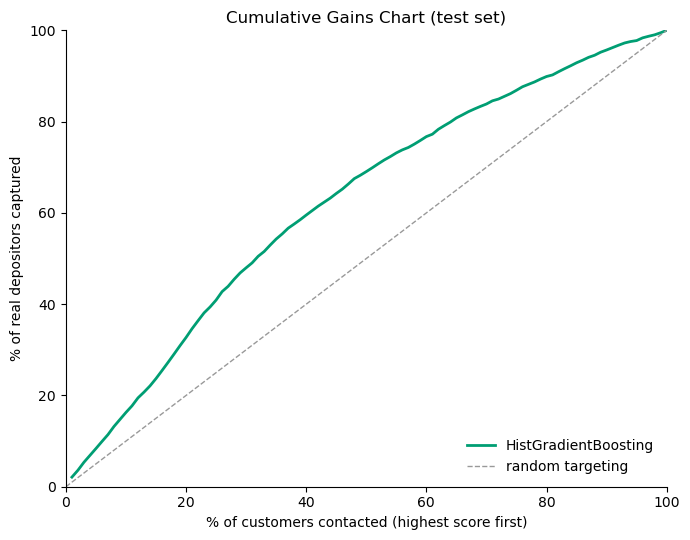

In [17]:
contacted_at = (fractions * n_total).astype(int)
contacted_at[contacted_at == 0] = 1
recall_curve = cum_positive[contacted_at - 1] / total_positive

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fractions * 100, recall_curve * 100, color=PALETTE[best_model_name], linewidth=2, label=best_model_name)
ax.plot([0, 100], [0, 100], linestyle="--", color="#999999", linewidth=1, label="random targeting")
ax.set_xlabel("% of customers contacted (highest score first)")
ax.set_ylabel("% of real depositors captured")
ax.set_title("Cumulative Gains Chart (test set)")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

### เลือก "โทร top กี่%" ยังไงให้มีเหตุผลทางธุรกิจรองรับ

ตัวเลข `gains_df`/กราฟด้านบนบอกแค่ว่า "โทรกี่% จับลูกค้าได้กี่%" แต่การเลือกจุดที่จะใช้จริงต้องอิงเหตุผลธุรกิจ 2 ตัวแปร: **ต้นทุนต่อการโทร 1 สาย (c)** และ **มูลค่าของลูกค้าที่ฝากจริง 1 คน (v)** บวกข้อจำกัดโควต้าการโทรถ้ามี — แบ่งได้เป็น 4 เคส:

**1) โควต้าโทรจำกัด (capacity-constrained)** เช่น call center โทรได้แค่ N สาย/แคมเปญ ไม่ว่าโมเดลแนะนำเท่าไหร่
- ดูตรงไหน: คอลัมน์ `n_contacted` หาแถวที่ใกล้โควต้าที่มี แล้วอ่าน `recall_%`/`customers_captured` ว่าจะจับได้กี่คน และดู `lift_x` ยืนยันว่าคุ้มกว่าสุ่มโทรกี่เท่า
- ทำไม: constraint จริงคือ "จำนวนสาย" ไม่ใช่เงิน การเลือกจึงไม่ใช่ optimize แต่คือใช้โควต้าที่มีให้คุ้มสุด

**2) ต้นทุนต่อสายแพง (precision-first)** เช่น relationship manager โทรเอง (เวลาแพง) หรือต้องรายงาน conversion rate ต่อผู้บริหาร
- ดูตรงไหน: คอลัมน์ `precision_%`/`lift_x` ที่ top N% ต่ำ ๆ (10–20%) เพราะ lift สูงสุดอยู่ตรงนั้น ยิ่ง N% มากขึ้น precision/lift ยิ่งลดลง (diminishing returns)
- ทำไม: เมื่อโทรแพง การพลาดลูกค้าบางคนเสียหายน้อยกว่าการโทรเปลืองสายที่แม่นน้อย

**3) ต้นทุนต่อสายถูกมาก / ห้ามพลาดลูกค้าเด็ดขาด (recall-first)** เช่น ใช้ auto-dialer/SMS ต้นทุนต่อคนแทบศูนย์ หรือโปรโมชันจำกัดเวลาที่พลาดแล้วลูกค้าหลุดไปคู่แข่งแน่ ๆ
- ดูตรงไหน: คอลัมน์ `recall_%` หา N% ต่ำสุดที่ยังให้ recall ถึงเป้า (เช่นต้องการ ≥80%)
- ทำไม: cost โทรผิดคนต่ำมากเทียบกับมูลค่าที่เสียถ้าพลาดคนที่จะฝากจริง จึงยอมโทรเยอะแลก recall สูง — นี่คือเคสที่ตรงกับโจทย์ "ไม่พลาดลูกค้า" ที่ตั้งไว้ตอนต้น

**4) อยากได้กำไรสุทธิสูงสุด ไม่มีข้อจำกัดตายตัว (profit-maximizing)** — เคสทั่วไปที่สุด เมื่อรู้ทั้ง c และ v จริง:

$$\text{กำไรคาดหวัง}(N\%) = \text{customers\_captured}(N\%) \times v - n\_contacted(N\%) \times c$$

- ดูตรงไหน: คำนวณสูตรนี้ทุกแถวของ `gains_df` แล้วเลือก N% ที่กำไรสูงสุด — จุดที่เหมาะสมในทางทฤษฎีคือจุดที่ "lift ส่วนเพิ่ม (marginal lift)" ลดลงมาเท่ากับอัตราส่วน c/v พอดี (ลูกค้าคนถัดไปในลิสต์ไม่คุ้มโทรอีกต่อไป)
- ทำไม: เป็นกรอบที่ unify ทุกเคสข้างบนในสูตรเดียว — เคส 1-3 เป็นแค่กรณีพิเศษของเคสนี้ (c→0 กลายเป็นเคส 3, มีแค่ budget ไม่มี v กลายเป็นเคส 1)

**สรุปสั้น ๆ:** ยิ่ง "ต้นทุนการพลาดลูกค้า" สูงกว่า "ต้นทุนการโทรผิดเป้า" มากเท่าไหร่ ยิ่งควรขยับไปทาง recall-first (โทรเยอะ, N% สูง) ยิ่งกลับกันคือยิ่งควรขยับไปทาง precision-first (โทรน้อยแต่แม่น, N% ต่ำ) — ถ้ามีตัวเลข c, v จริงจากธนาคาร คำนวณเคส 4 ได้ตรง ๆ โดยไม่ต้องเดา

### Feature importance (ตีความได้ว่าอะไรเป็นตัวบอกว่าใครจะฝากประจำ)

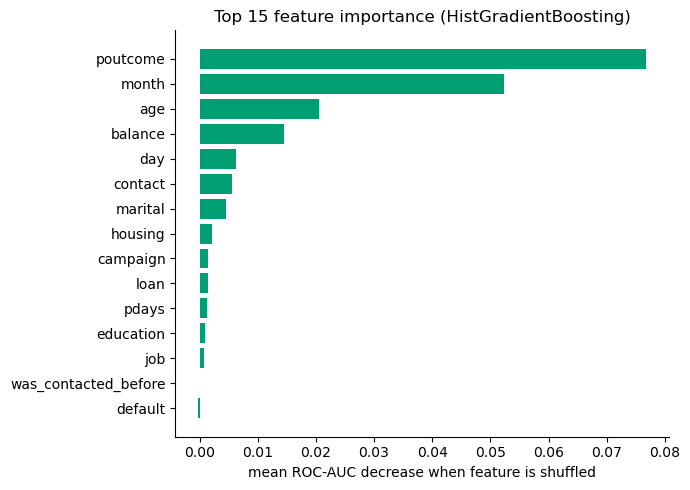

In [18]:
from sklearn.inspection import permutation_importance

# ใช้ permutation importance เพราะใช้ได้กับทุกโมเดล (HistGradientBoosting ไม่มี feature_importances_ ให้ใช้ตรง ๆ)
perm = permutation_importance(
    best_pipeline, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)

importance_df = (
    pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean})
    .sort_values("importance", ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance_df["feature"][::-1], importance_df["importance"][::-1], color=PALETTE[best_model_name])
ax.set_xlabel("mean ROC-AUC decrease when feature is shuffled")
ax.set_title(f"Top 15 feature importance ({best_model_name})")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### ตีความ feature importance: อะไรคือตัวบ่งชี้ที่แรงที่สุดว่าใครจะฝากประจำ

เรียงจากมีผลมากไปน้อย (วัดจาก ROC-AUC ที่ลดลงเมื่อสลับค่าฟีเจอร์นั้นแบบสุ่ม — ยิ่งลดมาก ยิ่งสำคัญ):

1. **`poutcome`** (ผลลัพธ์ของแคมเปญครั้งก่อน) — สำคัญที่สุดแบบทิ้งห่าง ลูกค้าที่เคย "success" ในแคมเปญก่อนหน้ามีแนวโน้มฝากประจำซ้ำสูงกว่าคนทั่วไปมาก → เป็น "ลูกค้าเก่าที่คุ้นเคยกับผลิตภัณฑ์" ควรจัดเป็นกลุ่มที่ติดต่อก่อน
2. **`month`** (เดือนที่ติดต่อ) — มีผลสูงเป็นอันดับ 2 สะท้อนว่าจังหวะ/ฤดูกาลของแคมเปญ (เช่น ช่วงอัตราดอกเบี้ยหรือพฤติกรรมการออมตามฤดูกาล) มีผลต่ออัตราการปิดดีลชัดเจน
3. **`age`**, **`balance`** — ลักษณะทางการเงิน/ช่วงวัยของลูกค้า มีผลรองลงมาแต่ยังชัดเจน (เช่น คนมียอดเงินในบัญชีสูงมีแนวโน้มพิจารณาฝากประจำมากกว่า)
4. ฟีเจอร์ที่เหลือ (`day`, `contact`, `marital`, `housing`, `campaign`, `loan`, `pdays`, `education`, `job`) มีผลค่อนข้างน้อยเมื่อเทียบกับ 4 ตัวแรก ส่วน `was_contacted_before` และ `default` แทบไม่มีผลเลยในโมเดลนี้

**นัยเชิงธุรกิจ:** ถ้าต้องเลือก "โทรหาใครก่อน" ภายใต้งบ/เวลาจำกัด ลำดับความสำคัญควรเริ่มจากลูกค้าที่มี `poutcome=success` ก่อนเป็นอันดับแรก ตามด้วยการเลือก "จังหวะเดือน" ที่ข้อมูลในอดีตปิดดีลได้ดี แล้วจึงพิจารณา `age`/`balance` เป็นตัวช่วยจัดลำดับรอง ๆ ลงมา — ใช้ร่วมกับกราฟ gains/lift ในหัวข้อถัดไปเพื่อกำหนดว่าจะ "โทร top กี่%"


## 8. Appendix A: ทำไมไม่ควรสลับข้อมูล — เทียบ time-based split กับ random split

ใช้โมเดลตัวเดียวกัน (`best_model_name`) ฝึกและวัดผลด้วยวิธีแบ่งข้อมูลสองแบบที่สัดส่วน 80/20 เท่ากัน เพื่อดูว่าตัวเลขต่างกันแค่ไหน

In [19]:
from sklearn.model_selection import train_test_split

X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(
    X, y, test_size=0.2, stratify=y, shuffle=True, random_state=RANDOM_STATE
)

pipeline_rand = make_pipeline(MODELS[best_model_name])
pipeline_rand.fit(X_train_rand, y_train_rand)
proba_rand = pipeline_rand.predict_proba(X_test_rand)[:, 1]

comparison = pd.DataFrame({
    "split": ["time-based (no shuffle)", "random (shuffle + stratify)"],
    "roc_auc": [roc_auc_score(y_test, y_proba), roc_auc_score(y_test_rand, proba_rand)],
    "pr_auc": [average_precision_score(y_test, y_proba), average_precision_score(y_test_rand, proba_rand)],
})
comparison

,split,roc_auc,pr_auc
0,time-based (no shuffle),0.679540,0.468455
1,random (shuffle + stratify),0.803674,0.460219


## 9. Appendix B: ผลของ `duration` ต่อ performance (ยืนยัน data leakage)

ลองใส่ `duration` กลับเข้าไปเป็นฟีเจอร์ แล้วเทียบ ROC-AUC บน test set เดิม (time-based) กับโมเดลที่ไม่มี `duration` — ถ้าคะแนนพุ่งขึ้นชัดเจนก็ยืนยันว่า `duration` คือตัวการ leakage ตามที่ตั้งข้อสังเกตไว้ และไม่ควรใช้งานจริงกับโมเดลที่ต้อง "เลือกเป้าหมายก่อนโทร"

In [20]:
FEATURES_WITH_DURATION = FEATURES + ["duration"]
NUMERIC_WITH_DURATION = NUMERIC_FEATURES + ["duration"]

preprocessor_dur = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ("num", StandardScaler(), NUMERIC_WITH_DURATION),
])

X_dur = model_df[FEATURES_WITH_DURATION]
X_train_dur, X_test_dur = X_dur.iloc[:split_idx], X_dur.iloc[split_idx:]

pipeline_dur = Pipeline([("prep", preprocessor_dur), ("clf", clone(MODELS[best_model_name]))])
pipeline_dur.fit(X_train_dur, y_train)
proba_dur = pipeline_dur.predict_proba(X_test_dur)[:, 1]

leakage_check = pd.DataFrame({
    "feature_set": ["ไม่มี duration (ใช้งานจริงได้)", "มี duration (เห็นผลหลังโทรแล้ว)"],
    "test_roc_auc": [roc_auc_score(y_test, y_proba), roc_auc_score(y_test, proba_dur)],
    "test_pr_auc": [average_precision_score(y_test, y_proba), average_precision_score(y_test, proba_dur)],
})
leakage_check

,feature_set,test_roc_auc,test_pr_auc
0,ไม่มี duration (ใช้งานจริงได้),0.679540,0.468455
1,มี duration (เห็นผลหลังโทรแล้ว),0.787219,0.556575


## 10. ทดลองแบ่งข้อมูลหลายสัดส่วน (60:40, 70:30, 80:20, 90:10) × หลายโมเดล

ทดลองสัดส่วน train:test 4 แบบ — ยังคงแบ่งแบบ **time-based ไม่สลับข้อมูล** เหมือนเดิม (ตัด positional ตามสัดส่วนที่กำหนด แถวต้น ๆ = train, แถวท้าย ๆ = test) เพื่อไม่ขัดกับเหตุผลเรื่อง time-order ที่อธิบายไว้ในข้อ 3 แล้วรัน 6 โมเดลเดิมบนแต่ละสัดส่วน รวมเป็นตาราง `model × split_ratio` เพื่อหาคู่ที่ดีที่สุด

**ข้อควรระวัง:** เพราะข้อมูลเรียงตามเวลา สัดส่วน test ที่ต่างกันจะมี "ช่วงเวลา" และสัดส่วนคลาส (`deposit=yes`) ต่างกันไปด้วย (เช่น test 10% ท้ายสุด vs test 40% ท้ายสุด ไม่ใช่กลุ่มตัวอย่างเดียวกันแค่สุ่มคนละขนาด) ดังนั้นเทียบกันตรง ๆ ด้วย ROC-AUC (ไม่ไวต่อสัดส่วนคลาสมากนัก) เป็นหลัก ส่วน PR-AUC ใช้ดูประกอบเท่านั้น

In [21]:
from sklearn.metrics import f1_score

SPLIT_RATIOS = {"60:40": 0.6, "70:30": 0.7, "80:20": 0.8, "90:10": 0.9}

split_results = []
for ratio_name, train_frac in SPLIT_RATIOS.items():
    idx = int(len(X) * train_frac)
    X_tr, X_te = X.iloc[:idx], X.iloc[idx:]
    y_tr, y_te = y.iloc[:idx], y.iloc[idx:]

    for model_name, estimator in MODELS.items():
        pipe = make_pipeline(estimator)
        pipe.fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        pred = pipe.predict(X_te)

        split_results.append({
            "split_ratio": ratio_name,
            "train_size": len(X_tr),
            "test_size": len(X_te),
            "test_positive_rate": y_te.mean(),
            "model": model_name,
            "roc_auc": roc_auc_score(y_te, proba),
            "pr_auc": average_precision_score(y_te, proba),
            "f1": f1_score(y_te, pred),
        })

split_results_df = pd.DataFrame(split_results)
ratio_order = list(SPLIT_RATIOS.keys())
split_results_df.pivot(index="model", columns="split_ratio", values="roc_auc")[ratio_order].round(3)

split_ratio,60:40,70:30,80:20,90:10
model,,,,
Dummy,0.500,0.500,0.500,0.500
HistGradientBoosting,0.612,0.668,0.680,0.605
LightGBM,0.568,0.643,0.619,0.597
LogisticRegression,0.620,0.677,0.684,0.614
RandomForest,0.536,0.581,0.620,0.600
XGBoost,0.540,0.609,0.620,0.584


In [ ]:
# กราฟเปรียบเทียบ ROC-AUC: จัดกลุ่มตามสัดส่วน train:test แกน x, แต่ละโมเดลสีคงที่ (ตาม PALETTE) ทุกกลุ่ม
model_names = list(MODELS.keys())
n_models = len(model_names)
bar_width = 0.8 / n_models
x = np.arange(len(ratio_order))

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, model_name in enumerate(model_names):
    vals = [split_results_df[(split_results_df.split_ratio == r) & (split_results_df.model == model_name)]["roc_auc"].iloc[0]
            for r in ratio_order]
    ax.bar(x + i * bar_width - 0.4 + bar_width / 2, vals, width=bar_width,
           label=model_name, color=PALETTE[model_name])

ax.set_xticks(x)
ax.set_xticklabels([f"{r} (train:test)" for r in ratio_order])
ax.set_ylabel("ROC-AUC (test set)")
ax.set_ylim(0.4, 1.0)
ax.set_title("Model comparison across train:test split ratios")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), borderaxespad=0, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [23]:
# หาคู่ (โมเดล, สัดส่วน) ที่ดีที่สุดจาก ROC-AUC บน test set จริง ไม่นับ Dummy (baseline เฉย ๆ)
candidates = split_results_df[split_results_df.model != "Dummy"]
best_split_row = candidates.loc[candidates["roc_auc"].idxmax()]

print(f"คู่ที่ดีที่สุด: model={best_split_row['model']}  split={best_split_row['split_ratio']}")
print(f"  roc_auc={best_split_row['roc_auc']:.3f}  pr_auc={best_split_row['pr_auc']:.3f}  f1={best_split_row['f1']:.3f}")
print(f"  train_size={best_split_row['train_size']}  test_size={best_split_row['test_size']}  test_positive_rate={best_split_row['test_positive_rate']:.1%}")
print()

split_results_df.sort_values("roc_auc", ascending=False).reset_index(drop=True).round(3)

คู่ที่ดีที่สุด: model=LogisticRegression  split=80:20
  roc_auc=0.684  pr_auc=0.488  f1=0.517
  train_size=36168  test_size=9043  test_positive_rate=31.6%



,split_ratio,train_size,test_size,test_positive_rate,model,roc_auc,pr_auc,f1
0,80:20,36168,9043,0.316,LogisticRegression,0.684,0.488,0.517
1,80:20,36168,9043,0.316,HistGradientBoosting,0.680,0.468,0.144
2,70:30,31647,13564,0.254,LogisticRegression,0.677,0.393,0.466
3,70:30,31647,13564,0.254,HistGradientBoosting,0.668,0.399,0.118
4,70:30,31647,13564,0.254,LightGBM,0.643,0.383,0.415
5,80:20,36168,9043,0.316,RandomForest,0.620,0.420,0.409
6,80:20,36168,9043,0.316,XGBoost,0.620,0.437,0.468
7,60:40,27126,18085,0.217,LogisticRegression,0.620,0.303,0.392
8,80:20,36168,9043,0.316,LightGBM,0.619,0.433,0.463
9,90:10,40689,4522,0.471,LogisticRegression,0.614,0.552,0.633


## 11. สรุป

- **ข้อมูลไม่สมดุล** (~12% deposit=yes) จึงใช้ `class_weight="balanced"` และดูผลด้วย ROC-AUC / PR-AUC / F1 ไม่ใช่ accuracy อย่างเดียว
- **ตัด `duration` ออก** เพราะเป็นข้อมูลที่รู้ได้หลังโทรไปแล้วเท่านั้น (ดู Appendix B สำหรับขนาดของ leakage ถ้าใส่เข้าไป) — ถ้าจะใช้โมเดลนี้ "ก่อน" โทร ต้องไม่มี `duration`
- **แบ่ง train/test แบบ time-based ไม่สลับข้อมูล** เพราะข้อมูลเรียงตามเวลาจริงและ use case คือพยากรณ์ล่วงหน้า — ผลเทียบกับ random split ใน Appendix A ใช้ตรวจสอบว่าการสุ่มทำให้คะแนนดูดีเกินจริงแค่ไหน
- **อธิบายหลักการของแต่ละอัลกอริทึม (ข้อ 4) ก่อนลงมือสร้างโมเดลจริง** พร้อมภาพ decision boundary บนข้อมูลของเล่น ให้เห็นว่า Logistic Regression ตัดเส้นตรง ส่วน Random Forest / HistGradientBoosting ตัดเป็นบล็อกไม่เป็นเส้นตรง
- **ทดลองหลายโมเดล (Logistic Regression / Random Forest / HistGradientBoosting / XGBoost / LightGBM) ร่วมกับหลาย CV scheme** (StratifiedKFold สุ่ม, KFold ไม่สุ่ม, TimeSeriesSplit) บน train set เพื่อเลือกโมเดลที่ performance เสถียรจริง ไม่ใช่ดีแค่บาง fold
- **ทดลองสัดส่วน train:test ทั้ง 60:40 / 70:30 / 80:20 / 90:10 × ทั้ง 6 โมเดล** (ข้อ 10) เพื่อดูว่าผลลัพธ์ไวต่อขนาด/ช่วงเวลาของ test set แค่ไหน — คู่ที่ดีที่สุดถูกเลือกจาก `roc_auc` สูงสุด (ดูตัวแปร `best_split_row`) โดยยังคงหลักการ time-based ไม่สลับข้อมูลทุกสัดส่วน
- **เพิ่ม XGBoost และ LightGBM เข้ามาเทียบ (ตอบคำถาม "ทำไมไม่ลองตัวอื่น")** ผลคือทั้งคู่ไม่ได้แรงกว่า Logistic Regression/HistGradientBoosting เลยในทุกรูปแบบการทดสอบ (section 6 และ 10) — อยู่กลางตารางเสมอ ทั้งที่เป็นมาตรฐานอุตสาหกรรมสำหรับ tabular data เพราะข้อมูลชุดนี้ไม่มี pattern ซับซ้อนพอให้ boosting ขั้นสูงได้เปรียบ และ distribution shift ตามเวลาเป็นตัวจำกัด performance หลักมากกว่าตัวเลือกอัลกอริทึม
- โมเดลที่เลือก (`best_model_name`) ถูกประเมินบน test set ที่ไม่เคยเห็นเพียงครั้งเดียว ป้องกันไม่ให้ตัดสินใจเลือกโมเดลจาก test set ซ้ำ ๆ (ซึ่งจะกลายเป็น leakage ทางอ้อม)
- **ลองปรับ decision threshold แบบตายตัวเพื่อลดการพลาดลูกค้า (ข้อ 7) แต่พบว่า "ไม่ robust"** — threshold ที่ tune จาก validation (positive rate 13.7%) ใช้กับ test (positive rate 31.6%) แล้วกลายเป็นทักว่า "yes" เกือบทุกคน (93% ของ test set) เพราะสัดส่วนคลาสเปลี่ยนไปตามเวลา (distribution shift) จึงใช้งานจริงไม่ได้
- **ทางแก้ที่ใช้งานได้จริง: ranking-based targeting ด้วย Cumulative Gains Chart** — เรียงลูกค้าตามคะแนนความน่าจะเป็นแล้วเลือกโทรหา "top N%" แทนการตัด threshold ตายตัว วิธีนี้ไม่ขึ้นกับ base rate ที่เปลี่ยนไป ดูตาราง `gains_df` เพื่อเลือกว่าจะโทรหากี่ % ตามกำลังคน/งบที่มี พร้อม recall/precision/lift ของแต่ละจุด
- Feature importance ช่วยบอกทีมการตลาดว่าปัจจัยไหนควรใช้จัดลำดับความสำคัญของลูกค้าที่จะโทรติดต่อ

## 12. ข้อจำกัดของโมเดลปัจจุบัน และแนวทางต่อยอด

**ข้อจำกัดที่ควรรู้ก่อนนำไปใช้จริง**
- **Concept drift ตามเวลา:** สัดส่วนลูกค้าที่ฝากประจำเปลี่ยนจาก 6.7% (train) เป็น 31.6% (test) — พฤติกรรมลูกค้า/บริบทตลาดเปลี่ยนไปตามช่วงเวลา โมเดลที่ train ด้วยข้อมูลเก่าอาจ "ล้าสมัย" เร็วกว่าที่คิด ควรมีแผน **retrain เป็นระยะ** (เช่น ทุกไตรมาส) ไม่ใช่ train ครั้งเดียวแล้วใช้ยาว ๆ
- **ROC-AUC ระดับ 0.68 ยังไม่สูงมาก:** โมเดลเรียนรู้ pattern ได้จริง (ดีกว่าสุ่ม) แต่ยังไม่ใช่โมเดลที่แม่นยำสูง เหมาะใช้เป็น **เครื่องมือจัดลำดับความสำคัญ (ranking/prioritization)** สำหรับทีม call center มากกว่าใช้ตัดสิน yes/no แบบเด็ดขาด
- **threshold ที่ tune จาก validation set ใช้ตรง ๆ กับอนาคตไม่ได้** (ดูหัวข้อ 7.2) เพราะสัดส่วนคลาสเปลี่ยนเร็ว การเลือกจุดตัดจึงควรอิงกราฟ gains/lift (หัวข้อ 7.3) ร่วมกับเหตุผลทางธุรกิจ (ต้นทุน/โควต้าการโทร) มากกว่าตั้งค่าคงที่ไว้ล่วงหน้า

**แนวทางต่อยอดที่ทำได้ต่อ**
1. **Calibration** (เช่น `CalibratedClassifierCV`) เพื่อให้ `predict_proba` สะท้อนความน่าจะเป็นจริง ไม่ใช่แค่ใช้จัดอันดับ
2. **เพิ่มฟีเจอร์เชิงเวลา/บริบทเศรษฐกิจ** เช่น อัตราดอกเบี้ยนโยบายช่วงนั้น ดัชนีความเชื่อมั่นผู้บริโภค เพื่อช่วยอธิบาย drift ที่เห็น
3. **Sliding-window retraining** แทนการ train ด้วยข้อมูลทั้งหมดครั้งเดียว เพื่อให้โมเดลตามทันพฤติกรรมล่าสุด
4. **Cost-sensitive decision** ผูก threshold เข้ากับต้นทุนโทร 1 สาย (c) และมูลค่าลูกค้าที่ฝากจริง (v) ตามแนวทางในหัวข้อ 7.4 แทนการใช้ 0.5 หรือ fixed recall target
